# - Importation des bibliotheques et configuration

In [84]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport
import warnings
import math

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")
pd.set_option('display.max_columns', None)


# - Chargement de dataset

In [34]:
df = pd.read_csv('../data/raw/mental_health.csv')

# - Audit initial (Valeurs manquantes,infos de dataset, shape, types et doublons)

In [15]:
display(df.head())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [16]:
display(df.tail())

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
1995,STU1996,23,Male,2,7.5,20.3,1.89,7.3,10.7,High,8.2,6.3,80.9,No,Average,No,Medium
1996,STU1997,21,Male,2,6.4,16.8,2.14,4.6,5.8,Moderate,4.6,3.5,76.9,Yes,Poor,No,High
1997,STU1998,19,Female,1,4.5,13.1,2.54,7.5,10.0,Low,6.7,8.1,87.9,Yes,NaN,No,High
1998,STU1999,21,Male,3,8.1,22.3,2.62,4.5,6.6,Moderate,6.5,8.4,100.0,No,Good,No,Low
1999,STU2000,19,Female,3,5.9,23.3,2.56,7.6,11.2,High,7.7,8.9,87.6,No,Average,No,Medium


In [17]:
df.dtypes

Student_ID                         object
Age                                 int64
Gender                             object
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                  object
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                      object
Diet_Quality                       object
Previous_Mental_Health_History     object
Mental_Health_Risk                 object
dtype: object

In [18]:
df.shape

(2000, 17)

In [19]:
# profile = ProfileReport(df, title="Rapport Risques de Santé Mentale", explorative=True)

# report_path = '../reports/profiling_report.html'
# profile.to_file(report_path)

In [20]:
print("-- les informations de dataset :")
df.info()

-- les informations de dataset :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   object 
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   object 
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   object 
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  A

In [21]:
print(f"\nNombre de doublons exacts : {df.duplicated().sum()}")


Nombre de doublons exacts : 0


In [22]:
print("\n--- Valeurs Manquantes ---")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])



--- Valeurs Manquantes ---
Sleep_Hours           62
GPA                   38
Social_Media_Hours    58
Financial_Stress      91
Family_Support        54
Attendance_Rate       47
Diet_Quality          69
dtype: int64


# - Statistiques descriptives des variables numeriques

In [23]:
# uniquement pour les colonnes numeriques (Age, GPA, Sleep_Hours, etc.)
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


- Classification des colonnes

In [ ]:
# Separer les colonnes selon leur type :

numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Nombre de colonnes numeriques :", len(numerical_cols))
print("Nombre de colonnes categorielles :", len(categorical_cols))

print("\nColonnes numeriques :")
print(numerical_cols)
print("\nColonnes categorielles :")
print(categorical_cols)

Nombre de colonnes numeriques : 10
Nombre de colonnes categorielles : 7

Colonnes numeriques :
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']

Colonnes categorielles :
['Student_ID', 'Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


- Analyse des valeurs numeriques

In [39]:
numeric_analysis = df[numerical_cols].agg(["count", "nunique", "min", "max", "mean", "median", "std"]).T

numeric_analysis["missing"] = df[numerical_cols].isnull().sum()

numeric_analysis["zeros"] = (df[numerical_cols] == 0).sum()

numeric_analysis["negative_values"] = (df[numerical_cols] < 0).sum()

numeric_analysis.sort_values(by="negative_values", ascending=False)

,count,nunique,min,max,mean,median,std,missing,zeros,negative_values
Age,2000.0,13.0,17.0,29.00,21.131500,21.00,2.139275,0,0,0
Year_of_Study,2000.0,5.0,1.0,5.00,2.630000,2.00,1.316802,0,0,0
Sleep_Hours,1938.0,66.0,3.3,10.00,6.758875,6.70,1.127072,62,0,0
Study_Hours_Per_Week,2000.0,284.0,2.4,38.30,19.997900,19.80,5.719274,0,0,0
GPA,1962.0,182.0,1.5,3.66,2.562503,2.56,0.343993,38,0,0
Social_Media_Hours,1942.0,71.0,2.1,10.00,6.013955,6.00,1.153422,58,0,0
Screen_Time_Hours,2000.0,95.0,3.3,14.00,8.548500,8.50,1.657571,0,0,0
Financial_Stress,1909.0,87.0,1.4,10.00,5.956260,6.10,1.893941,91,0,0
Family_Support,1946.0,82.0,1.7,9.90,6.518345,6.70,1.844639,54,0,0
Attendance_Rate,1953.0,313.0,54.4,100.00,85.080236,85.10,7.224118,47,0,0


# - Verification des valeurs impossibles

In [ ]:
# Definir les limites logiques :

rules = {
    "Age": (15, 100),
    "Sleep_Hours": (0, 24),
    "Year_of_Study": (1, 10),
    "Sleep_Hours": (0, 24),
    "Social_Media_Hours": (0, 24),
    "Attendance_Rate": (0, 100),
    "Financial_Stress": (0, 10),
    "Family_Support": (0, 10),
}

for col, (min_val, max_val) in rules.items():

    invalid = df[(df[col] < min_val) | (df[col] > max_val)]
    print(f"\n--- {col} ---")
    print("Valeurs suspectes :", len(invalid))
    if len(invalid) > 0:
        display(invalid[[col]].head(10))


--- Age ---
Valeurs suspectes : 0

--- Sleep_Hours ---
Valeurs suspectes : 0

--- Year_of_Study ---
Valeurs suspectes : 0

--- Social_Media_Hours ---
Valeurs suspectes : 0

--- Attendance_Rate ---
Valeurs suspectes : 0

--- Financial_Stress ---
Valeurs suspectes : 0

--- Family_Support ---
Valeurs suspectes : 0


- Corrélation entre les variables numériques

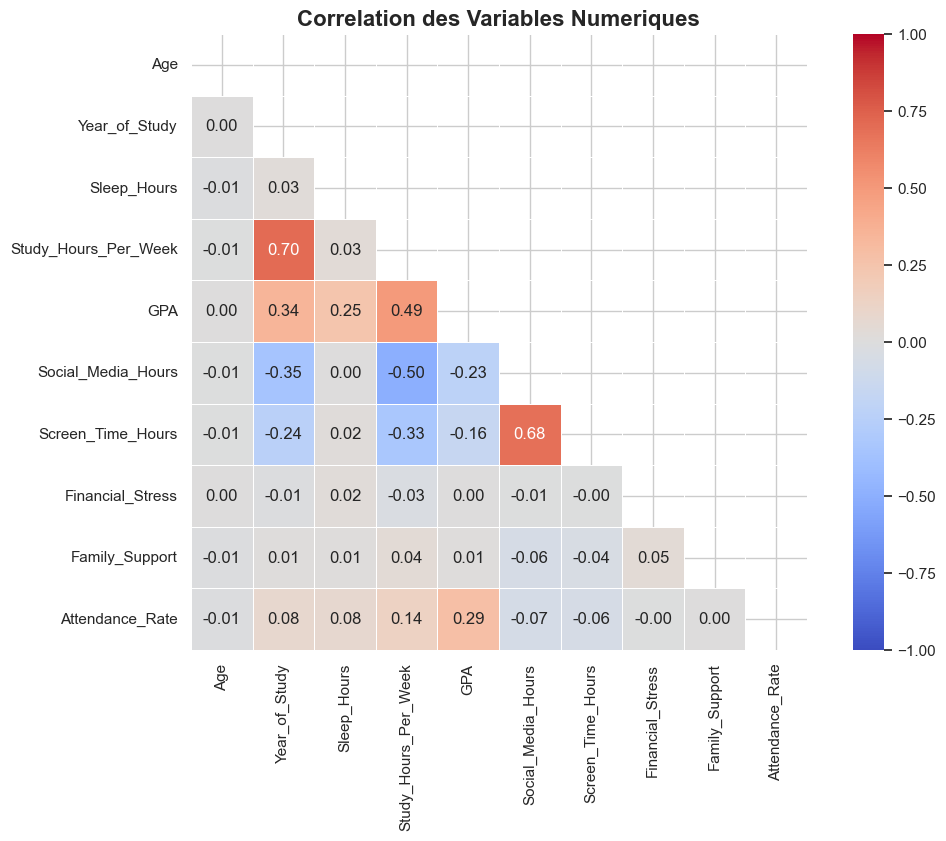

In [83]:
plt.figure(figsize=(12, 8))
correlation_matrix = df[numerical_cols].corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
            vmin=-1, vmax=1, square=True, linewidths=.5)

plt.title("Correlation des Variables Numeriques", fontsize=16, fontweight='bold')
plt.show()

- Relation entre Age et Year_of_Study

,count,min,max,mean,median
Year_of_Study,,,,,
1,509,17,27,21.133595,21.0
2,500,17,28,21.094000,21.0
3,426,17,27,21.183099,21.0
4,352,17,29,21.119318,21.0
5,213,17,26,21.131455,21.0


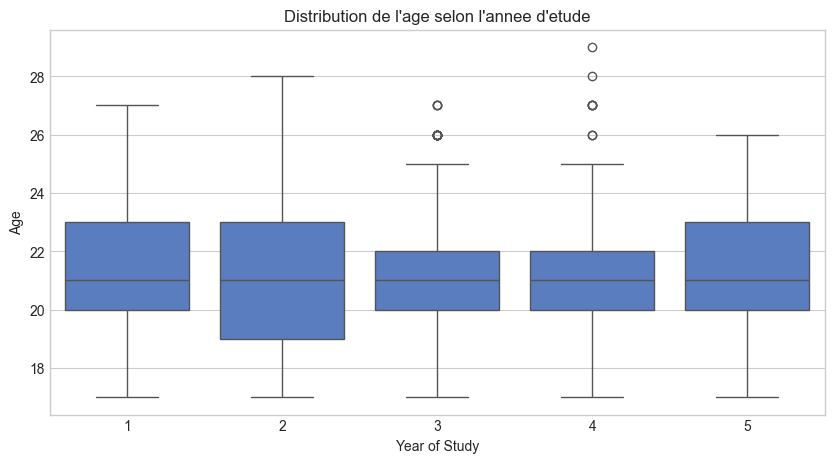

In [52]:
display(df.groupby("Year_of_Study")["Age"].agg([ "count", "min", "max", "mean", "median" ]))
plt.figure(figsize=(10, 5))
sns.boxplot(data=df,  x="Year_of_Study", y="Age")

plt.title("Distribution de l'age selon l'annee d'etude")
plt.xlabel("Year of Study")
plt.ylabel("Age")
plt.show()

- Description des colonnes :

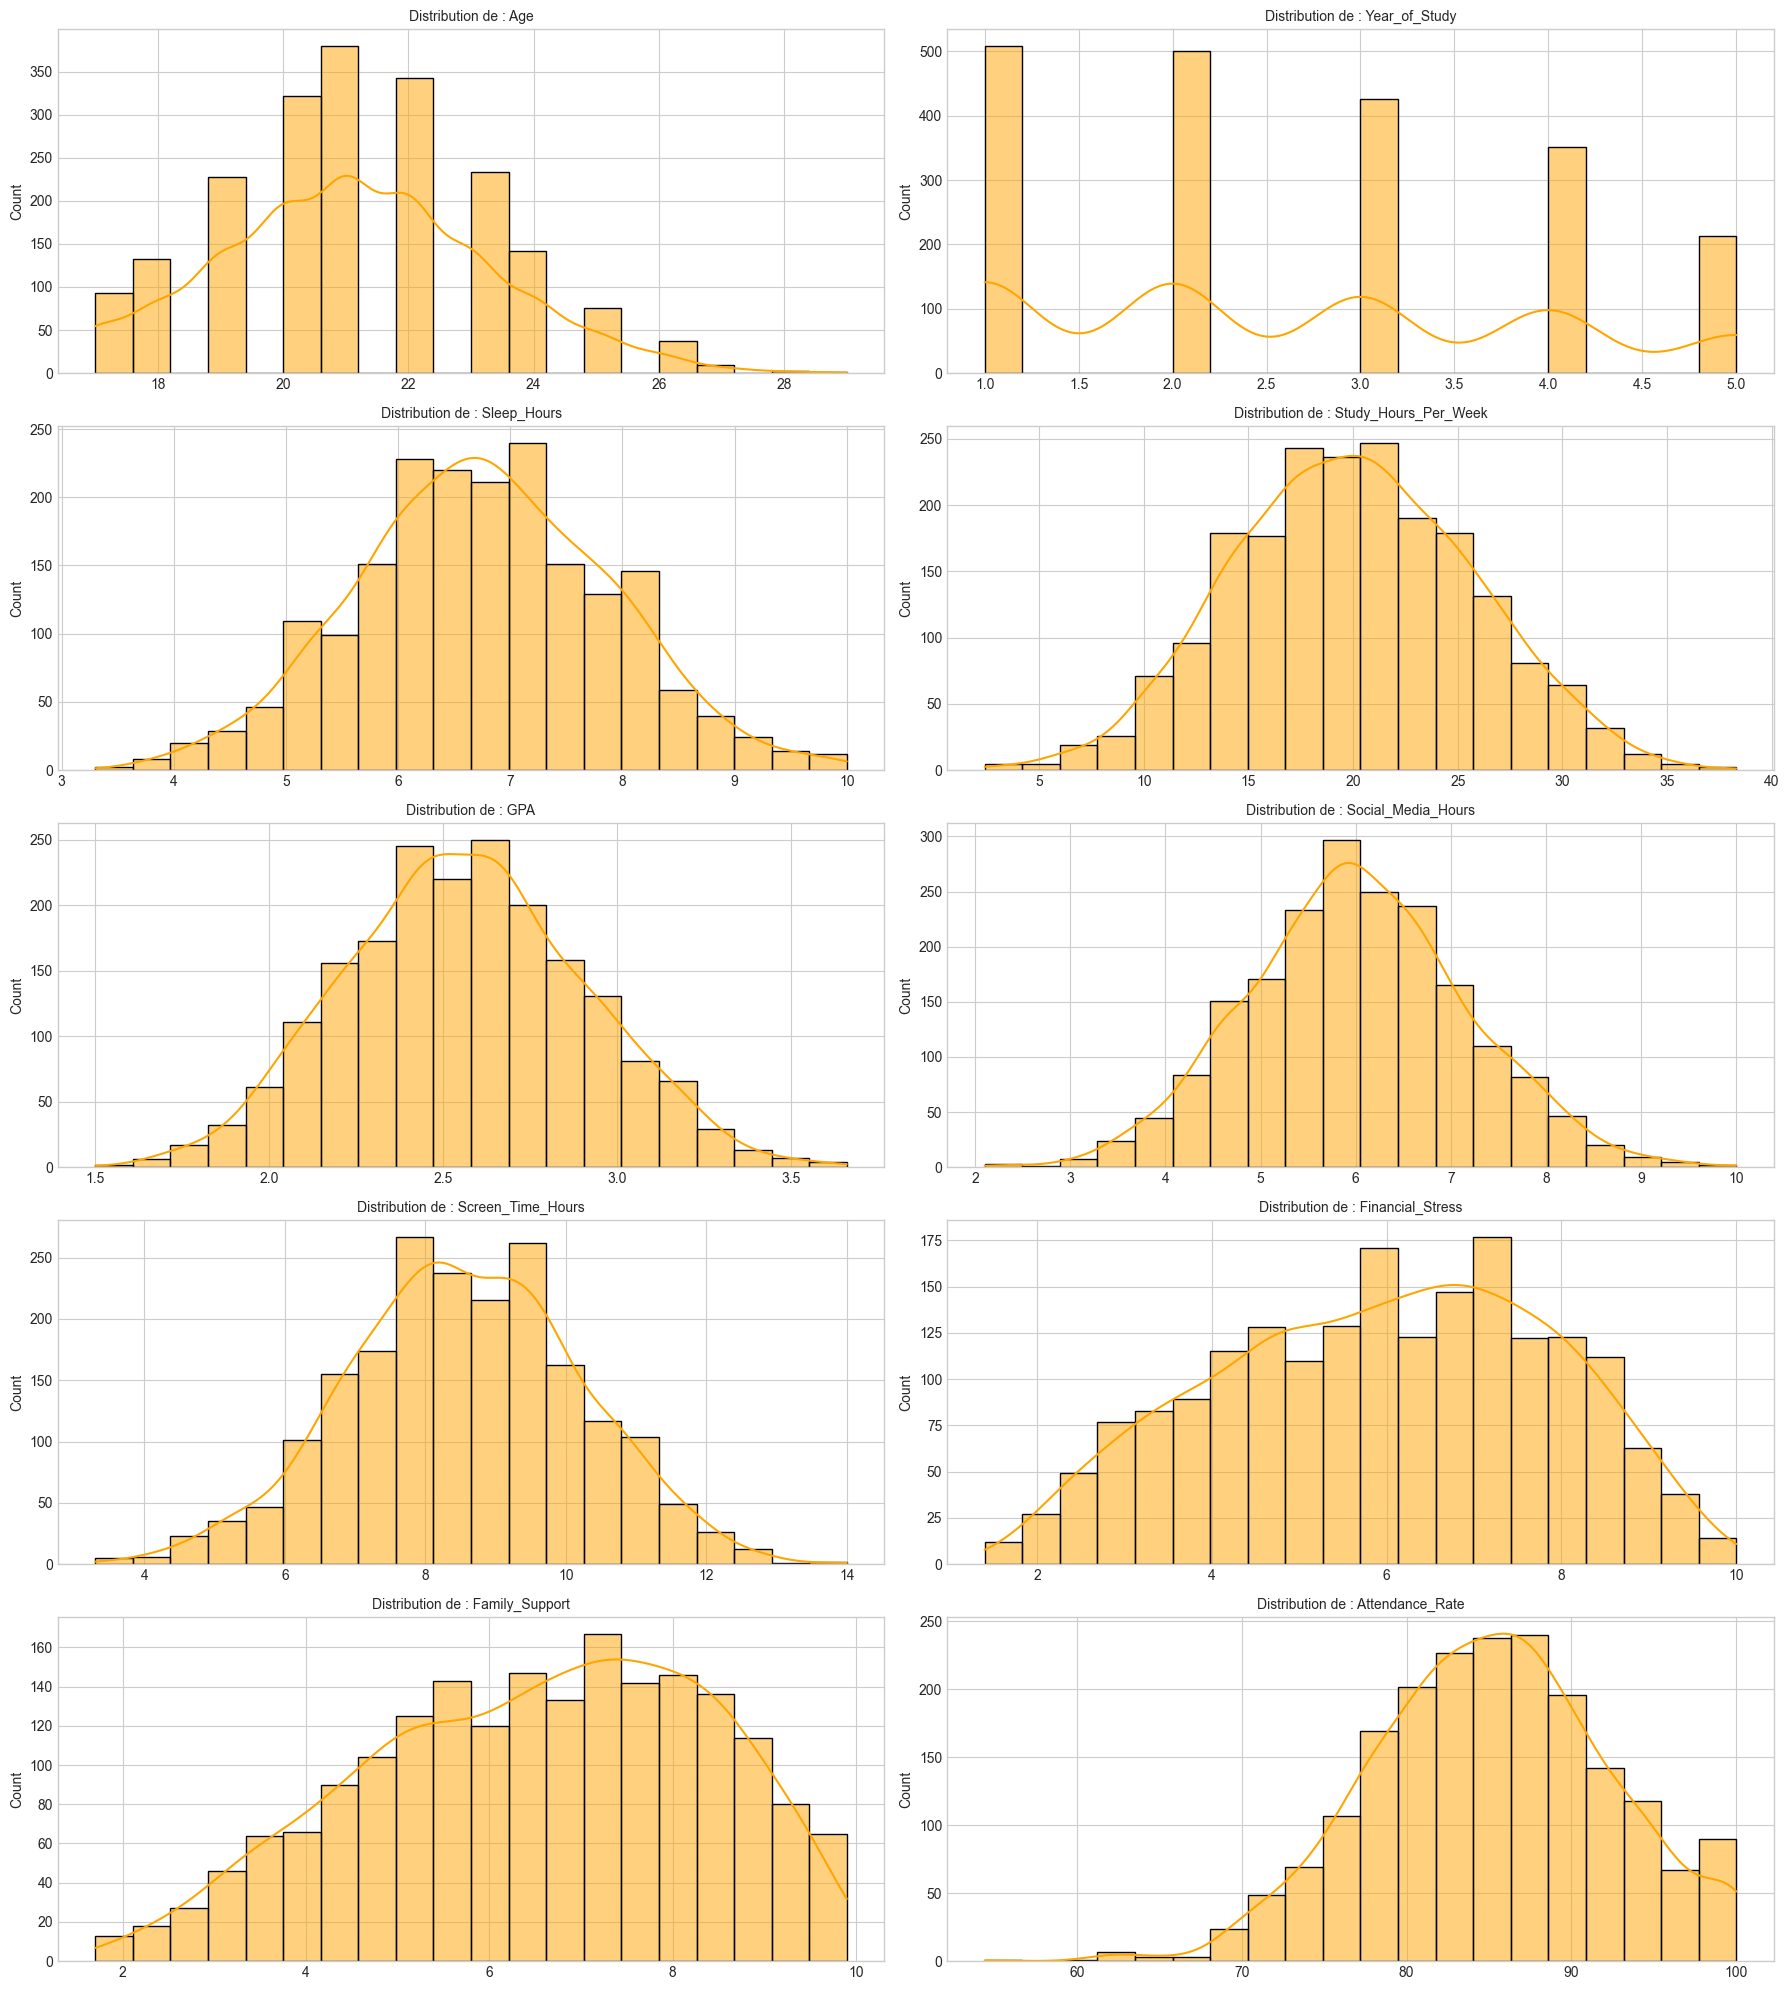

In [ ]:

cols_num = df.select_dtypes(include=['float64', 'int64']).columns
n_cols = len(cols_num) 

n_cols_plot = 2
n_rows_plot = math.ceil(n_cols / n_cols_plot) 

fig, axes = plt.subplots(nrows=n_rows_plot, ncols=n_cols_plot, figsize=(18, 4 * n_rows_plot))
axes = axes.flatten()

for i, col in enumerate(cols_num):
    sns.histplot(df[col], kde=True, ax=axes[i], color='orange', bins=20)
    axes[i].set_title(f'Distribution de : {col}', fontsize=10)
    axes[i].set_xlabel('')

for j in range(n_cols, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# analyse et detection les outliyers  :

In [ ]:
outliers_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    outliers_results.append({
        "Column": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outliers_Count": len(outliers),
        "Outliers_Percentage": round(len(outliers) / len(df) * 100, 2)
    })

outliers_df = pd.DataFrame(outliers_results)

display( outliers_df.sort_values(by="Outliers_Count", ascending=False ))

,Column,Lower_Bound,Upper_Bound,Outliers_Count,Outliers_Percentage
5,Social_Media_Hours,3.0125,8.9125,20,1.00
9,Attendance_Rate,65.7500,104.5500,12,0.60
4,GPA,1.6150,3.4950,9,0.45
3,Study_Hours_Per_Week,4.0000,36.0000,7,0.35
6,Screen_Time_Hours,3.9500,13.1500,7,0.35
0,Age,15.5000,27.5000,4,0.20
2,Sleep_Hours,3.6000,10.0000,2,0.10
1,Year_of_Study,-3.5000,8.5000,0,0.00
7,Financial_Stress,0.1500,11.7500,0,0.00
8,Family_Support,0.7500,12.3500,0,0.00


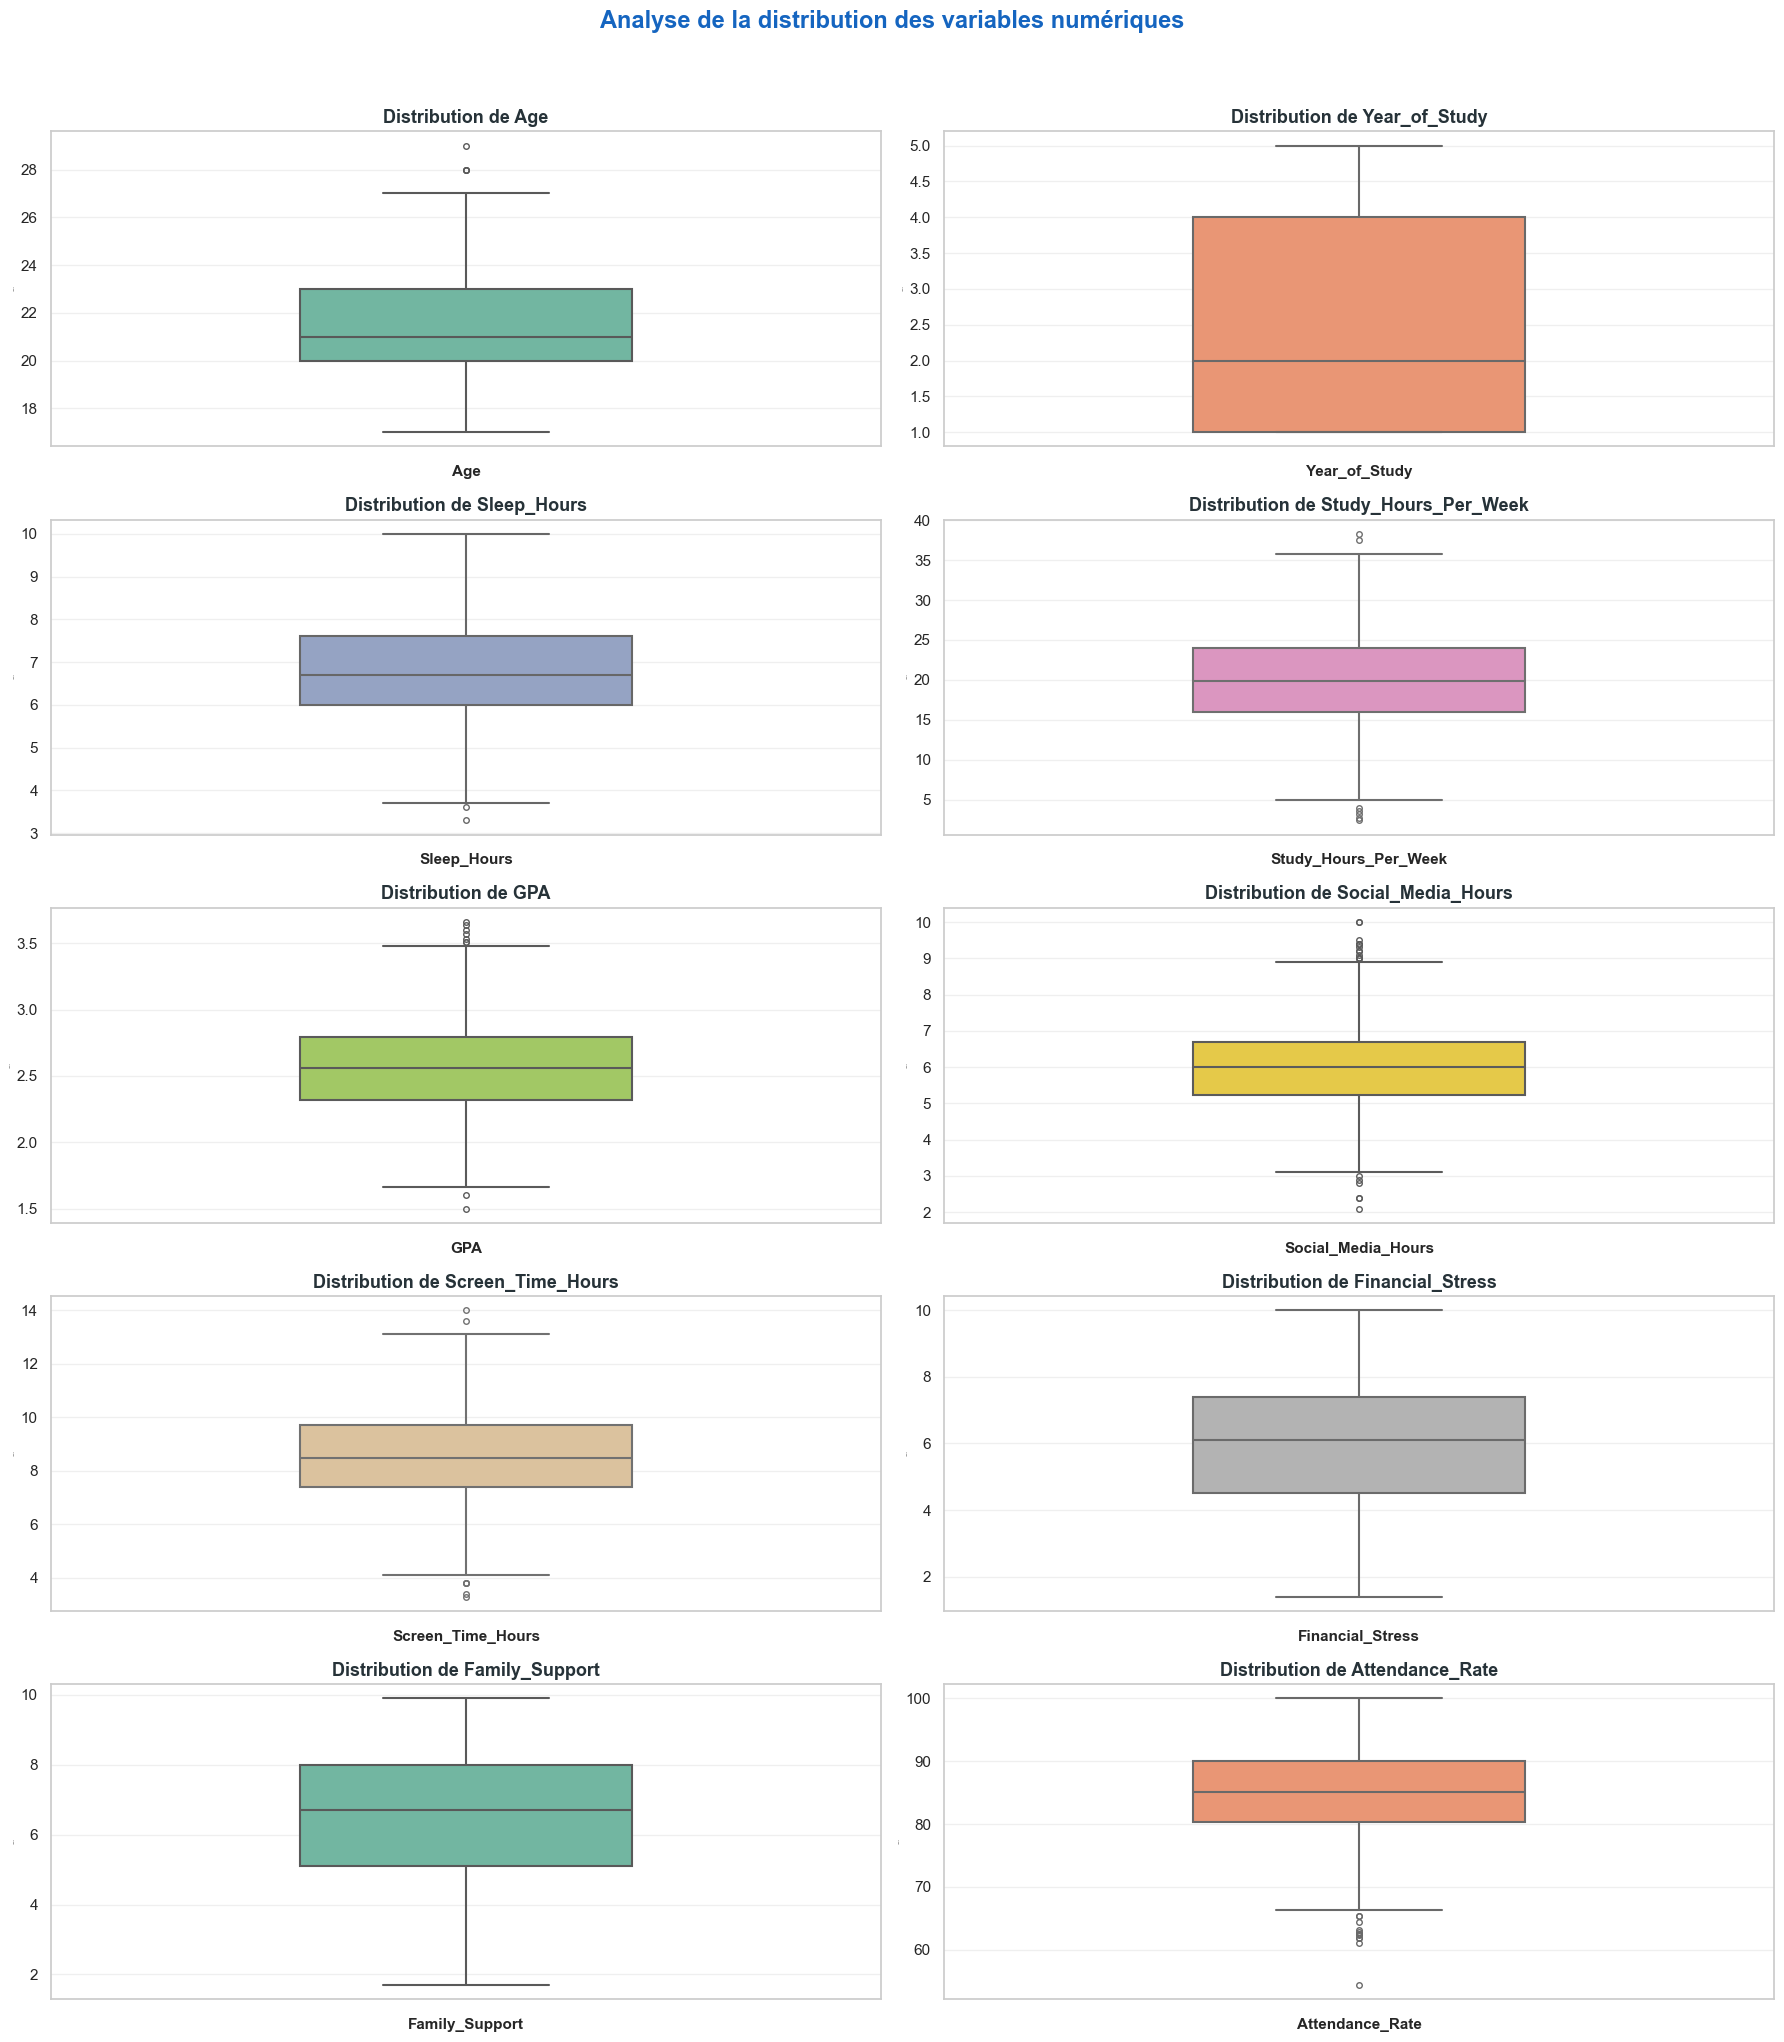

In [ ]:
sns.set_theme(style="whitegrid", palette="Set2")

fig, axes = plt.subplots( nrows=n_rows_plot, ncols=n_cols_plot, figsize=(18, 4 * n_rows_plot))

axes = axes.flatten()

colors = sns.color_palette("Set2", len(cols_num))

for i, col in enumerate(cols_num):

    sns.boxplot(y=df[col],ax=axes[i],color=colors[i],width=0.4,linewidth=1.5,fliersize=4 )

    axes[i].set_title(f"Distribution de {col}", fontsize=13, fontweight="bold", color="#263238")

    axes[i].set_xlabel(col,fontsize=11,fontweight="bold")

    axes[i].set_ylabel( "Valeurs", fontsize=1)

    axes[i].grid(axis="y", alpha=0.3)

for j in range(len(cols_num), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Analyse de la distribution des variables numériques",fontsize=17, fontweight="bold",  color="#1565C0", y=1.02)

plt.tight_layout()
plt.show()


- Les étudiants qui y a un age plus que le nombre des annees étudier :

In [85]:
suspicious_students = df[
    (df["Age"] < 18) &
    (df["Year_of_Study"] > 1)
]

print("Nombre de cas a verifier :", len(suspicious_students))

display(suspicious_students)

Nombre de cas a verifier : 70


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
13,STU0014,17,Female,2,5.4,17.0,2.40,6.6,10.5,Low,7.0,NaN,84.1,Yes,Average,Yes,High
14,STU0015,17,Male,4,6.3,23.3,2.83,4.5,6.3,Low,8.7,5.7,77.4,No,Good,No,High
37,STU0038,17,Female,5,6.3,28.2,2.33,6.0,6.7,Moderate,3.3,8.3,92.7,No,Poor,Yes,Medium
79,STU0080,17,Female,3,8.1,22.1,2.23,5.8,9.4,Moderate,5.3,8.1,82.9,No,Average,No,Low
142,STU0143,17,Female,2,6.6,15.4,2.55,6.7,9.4,Low,3.9,2.5,84.5,No,Poor,Yes,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1865,STU1866,17,Female,2,6.8,21.5,2.90,NaN,9.3,High,6.5,8.6,92.0,Yes,Good,Yes,Medium
1878,STU1879,17,Male,5,5.1,27.1,2.64,7.2,9.8,Moderate,4.8,7.5,81.2,No,Average,No,Medium
1914,STU1915,17,Non-binary,5,5.3,20.6,2.15,6.6,10.4,Moderate,8.1,8.1,73.4,Yes,Average,No,High
1920,STU1921,17,Female,5,7.4,22.7,2.35,6.7,7.0,Low,8.8,6.5,83.2,No,Average,No,High


- Analyse des relations entre variables catégorielles

In [87]:
for col in categorical_cols:

    print(f"\n===== {col} =====")

    print("Nombre de valeurs uniques :", df[col].nunique())

    display( df[col].value_counts(dropna=False))


===== Student_ID =====
Nombre de valeurs uniques : 2000


Student_ID
STU0001    1
STU0002    1
STU0003    1
STU0004    1
STU0005    1
          ..
STU1996    1
STU1997    1
STU1998    1
STU1999    1
STU2000    1
Name: count, Length: 2000, dtype: int64


===== Gender =====
Nombre de valeurs uniques : 3


Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64


===== Physical_Activity =====
Nombre de valeurs uniques : 3


Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

... (4 outputs left out)


===== Previous_Mental_Health_History =====
Nombre de valeurs uniques : 2


Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64


===== Mental_Health_Risk =====
Nombre de valeurs uniques : 3


Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

In [ ]:

# Convertir les heures d'étude hebdomadaires
# en moyenne journalière

df["Study_Hours_Per_Day"] = ( df["Study_Hours_Per_Week"] / 7
)

df["Total_days_Hours"] = ( df["Sleep_Hours"] + df["Screen_Time_Hours"] + df["Study_Hours_Per_Day"])

time_problems = df[ df["Total_days_Hours"] > 24 ]

print("Nombre de cas suspects :", len(time_problems))


time_problems[[ "Student_ID", "Sleep_Hours", "Screen_Time_Hours", "Study_Hours_Per_Week", "Total_days_Hours" ]]



Nombre de cas suspects : 3


,Student_ID,Sleep_Hours,Screen_Time_Hours,Study_Hours_Per_Week,Total_days_Hours
650,STU0651,9.8,11.0,24.6,24.314286
1497,STU1498,8.8,12.7,19.3,24.257143
1550,STU1551,8.4,12.7,20.7,24.057143


# - Vérifier les heures des réseaux sociaux et les heures de screen time :

In [97]:

social_media_problems = df[ df["Social_Media_Hours"] > df["Screen_Time_Hours"]]

print("Nombre de cas :", len(social_media_problems))

print(social_media_problems[
        [
            "Student_ID",
            "Social_Media_Hours",
            "Screen_Time_Hours"
        ]
    ]
)


Nombre de cas : 37
     Student_ID  Social_Media_Hours  Screen_Time_Hours
78      STU0079                 5.0                4.9
168     STU0169                 5.6                5.3
209     STU0210                 7.5                7.3
278     STU0279                 6.0                5.1
382     STU0383                 5.3                4.1
424     STU0425                 5.5                4.4
476     STU0477                 5.5                5.3
505     STU0506                 5.6                5.5
557     STU0558                 4.6                4.4
588     STU0589                 5.7                5.3
628     STU0629                 4.9                4.6
641     STU0642                 5.4                4.8
718     STU0719                 6.2                5.9
758     STU0759                 7.1                6.1
784     STU0785                 7.9                6.9
942     STU0943                 5.8                5.7
951     STU0952                 5.4           

# - analysis la relation entre study hours per week et attendance rate :

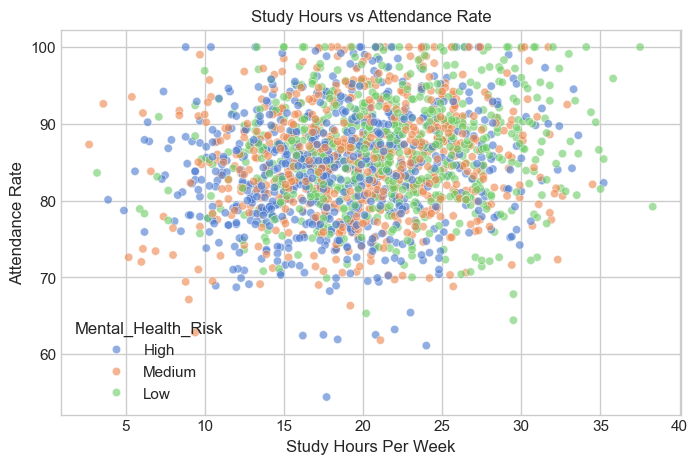

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot( data=df, x="Study_Hours_Per_Week", y="Attendance_Rate", hue="Mental_Health_Risk", alpha=0.6)

plt.title("Study Hours vs Attendance Rate")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Attendance Rate")
plt.show()



# - aNalysis la relation entre Physical Activity et Sleep Hours

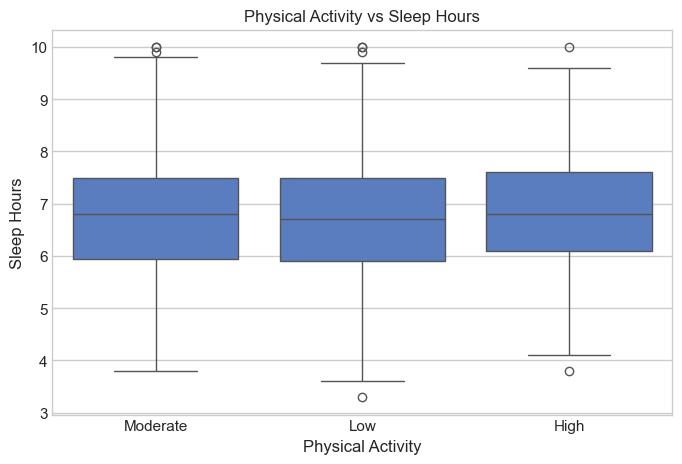

In [102]:

plt.figure(figsize=(8, 5))

sns.boxplot( data=df,  x="Physical_Activity", y="Sleep_Hours")

plt.title("Physical Activity vs Sleep Hours")
plt.xlabel("Physical Activity")
plt.ylabel("Sleep Hours")

plt.show()
